# Studio Proyek 3 — Fine-Tuning Transformer Pretrained untuk Klasifikasi Sentimen (SmSA)
**Pembelajaran Mendalam (IF25-40401) · ITERA**

Alur notebook: Konfigurasi → **Rancangan (Soal 1)** → Data → Utilitas freezing → Training → Jalankan matriks → Agregasi → Grafik → Bahan analisis.

**Cara pakai**
1. Runtime GPU (T4). Kaggle: nyalakan *Internet* (buat download dataset & model).
2. Jalankan dengan `MODE = "smoke"` dulu (cuma beberapa menit) buat mastiin pipeline jalan.
3. Edit sel **Rancangan** pakai kata-kata kalian sendiri, ganti `MODE = "full"`, lalu Run All.
4. Kalau Colab putus, jalankan ulang: run yang sudah selesai otomatis di-skip (hasil disimpan per run ke CSV).

## Ringkasan 1 menit (baca ini dulu)

**Pertanyaan yang dijawab notebook ini:** model Transformer mana, dan cara melatihnya yang mana, yang paling cocok untuk mengklasifikasikan sentimen kalimat Bahasa Indonesia (negatif / netral / positif) di dataset SmSA?

**Hasil utama** (rata-rata ± SD dari 3 seed, data test 500 kalimat, run konfigurasi `9cc8e9`):

| Backbone | Full FT: F1 makro | Inferensi (ms/kalimat) | Waktu latih (s) | Parameter |
|---|---|---|---|---|
| **IndoBERT** | **0,879 ± 0,017** | 1,01 | 82 | 124 M |
| mBERT | 0,781 ± 0,007 | 1,29 | 108 | 178 M |
| DistilBERT-m | 0,740 ± 0,010 | **0,67** | **61** | 135 M |

Pembanding: baseline TF-IDF F1 makro 0,754 (data latih penuh) dan 0,684 (subset 5.000); tebakan acak ≈ 0,33.

**Empat pesan penting**
1. **IndoBERT menang telak** (+9,8 poin F1 atas mBERT) dan juga lebih cepat serta lebih kecil dari mBERT. Penyebab yang masuk akal: ia dipralatih khusus pada teks Indonesia.
2. **Untuk IndoBERT, membekukan separuh lapisan awal (partial) hampir tidak menurunkan akurasi** (0,878 vs 0,879; selisihnya jauh di dalam noise antar-seed), tetapi waktu latih turun ±42% dan memori puncak ±46%.
3. **Linear probing murah tetapi jauh lebih lemah** pada protokol utama (IndoBERT 0,724; mBERT 0,407). Diagnostik 8c menunjukkan sebagian penyebabnya adalah kurang terlatih (3 epoch), bukan hanya keterbatasan metodenya.
4. **mBERT dan DistilBERT-m dengan partial atau probing berada di dekat atau di bawah baseline TF-IDF.** Pada IndoBERT, hanya full dan partial yang jelas melampauinya.

---

## Peta notebook & kamus istilah

**Alur:** Konfigurasi → Rancangan (Soal 1) → Data → Baseline TF-IDF → Fungsi freezing → Fungsi training → Jalankan 27 run → Agregasi → Grafik → Bahan analisis → Pemeriksaan hipotesis & baseline → Diagnostik probing → Kesimpulan.

| Istilah | Arti sederhana |
|---|---|
| **Backbone** | Model dasar yang sudah dipralatih (di sini: mBERT, DistilBERT-m, IndoBERT). |
| **Fine-tuning** | Melatih ulang backbone dengan data tugas kita supaya jago di tugas itu. |
| **Head replacement** | Mengganti lapisan terakhir model dengan lapisan baru berisi 3 keluaran (negatif/netral/positif). |
| **Full** | Semua parameter ikut dilatih. |
| **Partial freezing** | Embedding + separuh lapisan awal "dibekukan" (tidak dilatih), sisanya dilatih. |
| **Linear probing** | Seluruh backbone dibekukan, hanya head baru yang dilatih. |
| **Seed** | Angka pengacak. Mengulang dengan 3 seed berbeda menunjukkan seberapa stabil hasilnya. |
| **F1 makro** | Rata-rata F1 ketiga kelas dengan bobot sama, jadi kelas netral yang jarang tetap dihitung adil. Lebih jujur daripada akurasi. |
| **± SD** | Sebaran hasil antar-seed. Selisih antar-model yang lebih kecil dari SD tidak bisa dianggap berbeda. |
| **Baseline TF-IDF** | Model sederhana tanpa Transformer, dipakai sebagai pembanding yang sah. |


In [ ]:
import os, gc, time, json, hashlib, warnings
import numpy as np, pandas as pd
import torch
from torch.utils.data import DataLoader
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          get_linear_schedule_with_warmup, set_seed)
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

device = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = device == "cuda"
print("device:", device, "|", torch.cuda.get_device_name(0) if USE_AMP else "TANPA GPU (akan sangat lambat)")

device: cuda | Tesla T4


## 0. Konfigurasi (variabel yang dikunci)
Semua run memakai nilai yang sama persis. Hanya **seed**, **backbone**, dan **strategi** yang berubah.

In [ ]:
# APA YANG DILAKUKAN SEL INI: menetapkan semua pengaturan eksperimen (backbone, strategi, learning rate, ukuran batch, epoch, seed).
# Nilai di sini dikunci sama untuk semua run. Mengubahnya akan mengubah KODE konfigurasi dan seluruh matriks harus dijalankan ulang.
MODE = "full"          # "smoke" = uji cepat | "full" = eksperimen sebenarnya (wajib isi sel Rancangan)
DATASET = "smsa"

# --- Backbone (hanya model multibahasa / Indonesia; model English-only DILARANG di SmSA) ---
BACKBONES = {
    "BERT-mBERT":   "bert-base-multilingual-cased",         # wajib (baseline)
    "DistilBERT-m": "distilbert-base-multilingual-cased",   # wajib
    "IndoBERT":     "indobenchmark/indobert-base-p1",       # wajib untuk SmSA
}
INCLUDE_XLMR = False    # opsional (nilai plus): True -> tambah xlm-roberta-base (+9 run)
if INCLUDE_XLMR:
    BACKBONES["XLM-R"] = "xlm-roberta-base"

# --- Strategi. "head replacement" otomatis di semua run (num_labels=3). Minimal full + (probing ATAU partial) ---
STRATEGIES = ["full", "partial", "probing"]   # buang salah satu dari partial/probing kalau waktu mepet (18 run)
LR = {"full": 3e-5, "partial": 3e-5, "probing": 2e-3}   # sesuai ketentuan: 2e-5..5e-5 / 1e-3..5e-3

if MODE == "full":
    CFG = dict(max_len=128, batch=32, epochs=3, train_subset=5000, warmup=0.1, wd=0.01, data_seed=42)
    SEEDS = [42, 123, 2026]       # minimal 3 seed, SAMA untuk semua run
else:
    CFG = dict(max_len=64,  batch=32, epochs=1, train_subset=256,  warmup=0.1, wd=0.01, data_seed=42)
    SEEDS = [42]

# Opsional: bagi kerja antar-anggota. Contoh: ONLY_BACKBONES = ["IndoBERT"]
ONLY_BACKBONES = None
# Opsional: gabungkan file hasil_*.csv dari anggota lain (upload dulu), isi nama filenya di sini
EXTRA_RESULT_FILES = []

CFG["select_best_epoch"] = True   # val dipakai memilih epoch terbaik
_hash_cfg = dict(mode=MODE, cfg=CFG, lr=LR, backbones=BACKBONES)
KODE = hashlib.md5(json.dumps(_hash_cfg, sort_keys=True).encode()).hexdigest()[:6]
RES_FILE = f"hasil_{DATASET}_{KODE}.csv"
AGG_FILE = f"rekap_agregat_{DATASET}_{KODE}.csv"
print("MODE:", MODE, "| kode konfigurasi:", KODE)
print("CFG:", CFG, "| SEEDS:", SEEDS)
print("File hasil:", RES_FILE, "|", AGG_FILE)

MODE: full | kode konfigurasi: 9cc8e9
CFG: {'max_len': 128, 'batch': 32, 'epochs': 3, 'train_subset': 5000, 'warmup': 0.1, 'wd': 0.01, 'data_seed': 42, 'select_best_epoch': True} | SEEDS: [42, 123, 2026]
File hasil: hasil_smsa_9cc8e9.csv | rekap_agregat_smsa_9cc8e9.csv


## 1. Rancangan Eksperimen (Soal 1)
> **Wajib diedit.** Isi di bawah ini draft awal — ubah pakai alasan & hipotesis kalian sendiri **sebelum** menjalankan eksperimen. Pada `MODE = "full"`, notebook menolak jalan kalau bagian ini kosong atau masih berisi `TODO`.

In [ ]:
# APA YANG DILAKUKAN SEL INI: menulis rancangan (hipotesis H1-H3, alasan desain, variabel terkendali). Ditulis SEBELUM eksperimen, jangan diubah setelah melihat hasil.
RANCANGAN = {
 "H1": "H1 (backbone): Dengan full fine-tuning, IndoBERT akan menghasilkan F1 makro tertinggi, diikuti mBERT lalu DistilBERT-m, "
       "karena IndoBERT dipralatih khusus pada teks Bahasa Indonesia sedangkan model multibahasa membagi kapasitasnya ke banyak bahasa.",
 "H2": "H2 (strategi): Urutan kualitas full > partial freezing > linear probing. Linear probing turun paling jauh (representasi beku "
       "tidak disesuaikan ke domain sentimen), tetapi waktu latih dan memori puncaknya paling kecil.",
 "H3": "H3 (efisiensi): DistilBERT-m (6 lapis vs 12) inferensinya jauh lebih cepat dari mBERT dengan penurunan F1 makro yang kecil, "
       "sehingga jadi pilihan terbaik kalau anggaran komputasi atau latensi dibatasi.",
 "alasan_dataset_dan_subset": "SmSA (IndoNLU) dipilih karena berbahasa Indonesia, 3 kelas (negatif/netral/positif), punya pembagian resmi train/valid/test. "
       "Train di-subsample stratified sebesar train_subset supaya 27 run muat di GPU T4 gratis; valid & test dipakai utuh.",
 "alasan_desain": "Matriks 3 backbone x 3 strategi x 3 seed = 27 run. Backbone dibatasi ke model multibahasa/Indonesia agar perbandingan tidak "
       "tercampur faktor bahasa. Learning rate disesuaikan per strategi (probing jauh lebih besar). Hasil dilaporkan rata-rata ± std antar-seed.",
}
RANCANGAN["variabel_terkendali"] = (
    f"max_length={CFG['max_len']}, batch_size={CFG['batch']}, epoch={CFG['epochs']}, train_subset={CFG['train_subset']}, "
    f"warmup={CFG['warmup']}, weight_decay={CFG['wd']}, optimizer=AdamW, lr={LR}, seed={SEEDS}, data_seed={CFG['data_seed']}, "
    f"fp16={USE_AMP}, pembagian data=resmi SmSA (dibersihkan)."
)

RANCANGAN["pemilihan_epoch"] = ("Data validasi dipakai HANYA untuk memilih epoch terbaik (F1 makro validasi tertinggi dari 3 epoch); "
                                "bobot epoch terbaik dipulihkan lalu test dievaluasi sekali per run.")

def cek_rancangan():
    kosong = [k for k, v in RANCANGAN.items() if len(str(v).strip()) < 30 or "TODO" in str(v)]
    if kosong and MODE == "full":
        raise RuntimeError(f"Sel Rancangan belum lengkap: {kosong}. Isi dulu sebelum mode full.")
    return kosong

print("Bagian rancangan bermasalah:", cek_rancangan() or "tidak ada")

# Tabel matriks backbone x strategi (rencana sel yang akan diisi)
matriks = pd.DataFrame({s: [f"{len(SEEDS)} seed" for _ in BACKBONES] for s in STRATEGIES}, index=list(BACKBONES))
matriks.index.name = "backbone \\ strategi"
display(matriks)
print("Total run:", len(BACKBONES) * len(STRATEGIES) * len(SEEDS))
for k, v in RANCANGAN.items(): print(f"\n[{k}] {v}")

Bagian rancangan bermasalah: tidak ada


,full,partial,probing
backbone \ strategi,,,
BERT-mBERT,3 seed,3 seed,3 seed
DistilBERT-m,3 seed,3 seed,3 seed
IndoBERT,3 seed,3 seed,3 seed


Total run: 27

[H1] H1 (backbone): Dengan full fine-tuning, IndoBERT akan menghasilkan F1 makro tertinggi, diikuti mBERT lalu DistilBERT-m, karena IndoBERT dipralatih khusus pada teks Bahasa Indonesia sedangkan model multibahasa membagi kapasitasnya ke banyak bahasa.

[H2] H2 (strategi): Urutan kualitas full > partial freezing > linear probing. Linear probing turun paling jauh (representasi beku tidak disesuaikan ke domain sentimen), tetapi waktu latih dan memori puncaknya paling kecil.

[H3] H3 (efisiensi): DistilBERT-m (6 lapis vs 12) inferensinya jauh lebih cepat dari mBERT dengan penurunan F1 makro yang kecil, sehingga jadi pilihan terbaik kalau anggaran komputasi atau latensi dibatasi.

[alasan_dataset_dan_subset] SmSA (IndoNLU) dipilih karena berbahasa Indonesia, 3 kelas (negatif/netral/positif), punya pembagian resmi train/valid/test. Train di-subsample stratified sebesar train_subset supaya 27 run muat di GPU T4 gratis; valid & test dipakai utuh.

[alasan_desain] Matriks 3 back

## 2. Data SmSA + pembersihan
Pembagian resmi. Dibuang: duplikat, teks berlabel bertentangan, dan teks validasi yang muncul di data latih.

**Singkatnya:** kita pakai pembagian data resmi SmSA, lalu membersihkan data supaya evaluasi adil. Pada run ini ada 67 duplikat di data latih (11.000 menjadi 10.933), tidak ada label bertentangan, dan ada 14 kalimat validasi yang bocor ke data latih; semuanya sudah dibuang. Data latih di-subsample 5.000 kalimat dengan proporsi kelas tetap, dan kelas netral memang paling sedikit.


In [ ]:
# APA YANG DILAKUKAN SEL INI: memuat data SmSA, membuang duplikat/label bertentangan/kebocoran validasi, lalu mengambil 5.000 data latih (stratified).
LABELS = ["negative", "neutral", "positive"]
L2I = {l: i for i, l in enumerate(LABELS)}
I2L = {i: l for l, i in L2I.items()}
BASE_URL = "https://raw.githubusercontent.com/IndoNLP/indonlu/master/dataset/smsa_doc-sentiment-prosa/"

def read_split(name):
    for p in [f"{name}_preprocess.tsv", f"/kaggle/input/smsa/{name}_preprocess.tsv", f"/content/{name}_preprocess.tsv"]:
        if os.path.exists(p):
            return pd.read_csv(p, sep="\t", header=None, names=["text", "label"])
    try:
        return pd.read_csv(BASE_URL + f"{name}_preprocess.tsv", sep="\t", header=None, names=["text", "label"])
    except Exception as e:
        raise RuntimeError(f"Gagal download {name}. Nyalakan Internet (Kaggle) atau upload {name}_preprocess.tsv "
                           f"dari repo IndoNLP/indonlu ke folder kerja. Detail: {e}")

raw = {s: read_split(s).dropna() for s in ["train", "valid", "test"]}
print({k: len(v) for k, v in raw.items()}, "(mentah)")

def drop_dup_conflict(df):
    n = df.groupby("text")["label"].nunique()
    bad = set(n[n > 1].index)
    out = df[~df["text"].isin(bad)].drop_duplicates("text").reset_index(drop=True)
    return out, len(bad)

train, n_bad_tr = drop_dup_conflict(raw["train"])
valid, n_bad_va = drop_dup_conflict(raw["valid"])
n_leak = valid["text"].isin(set(train["text"])).sum()
valid = valid[~valid["text"].isin(set(train["text"]))].reset_index(drop=True)
test = raw["test"].reset_index(drop=True)
n_test_overlap = test["text"].isin(set(train["text"])).sum()   # hanya info, tidak dibuang (test resmi)

for d in (train, valid, test):
    d["y"] = d["label"].map(L2I)
    assert d["y"].notna().all(), "ada label di luar negative/neutral/positive"
    d["y"] = d["y"].astype(int)

print(f"Dibuang -> teks label bertentangan: train {n_bad_tr}, valid {n_bad_va} | valid yang bocor di train: {n_leak}")
print(f"Info: kalimat test yang ada juga di train: {n_test_overlap}")
print({"train": len(train), "valid": len(valid), "test": len(test)}, "(bersih)")

if CFG["train_subset"] and CFG["train_subset"] < len(train):
    train_s, _ = train_test_split(train, train_size=CFG["train_subset"], stratify=train["y"], random_state=CFG["data_seed"])
    train_s = train_s.reset_index(drop=True)
else:
    train_s = train
print("Train dipakai:", len(train_s))
print("Distribusi kelas (train_s):", train_s["label"].value_counts().to_dict())
print("Distribusi kelas (test):   ", test["label"].value_counts().to_dict())

{'train': 11000, 'valid': 1260, 'test': 500} (mentah)
Dibuang -> teks label bertentangan: train 0, valid 0 | valid yang bocor di train: 14
Info: kalimat test yang ada juga di train: 0
{'train': 10933, 'valid': 1246, 'test': 500} (bersih)
Train dipakai: 5000
Distribusi kelas (train_s): {'positive': 2919, 'negative': 1560, 'neutral': 521}
Distribusi kelas (test):    {'positive': 208, 'negative': 204, 'neutral': 88}


## 2b. Baseline pembanding: TF-IDF + Logistic Regression

Spesifikasi menyebut baseline TF-IDF sebagai **pembanding yang sah**: sebuah model sederhana tanpa Transformer. Kalau fine-tuning tidak mengalahkannya, patut dicurigai ada yang salah (misalnya learning rate). Baseline ini hanya memakai CPU dan selesai dalam hitungan detik.

Dua versi dilaporkan: **data latih penuh** (pembanding resmi, ≈ 0,73 menurut spesifikasi) dan **subset 5.000** (yang dipakai Transformer, jadi lebih adil).


In [ ]:
# APA YANG DILAKUKAN SEL INI: melatih baseline TF-IDF + Logistic Regression dan menghitung F1 makro di data test.
# Hasilnya dipakai sebagai pembanding (selain tebakan acak = 1/3) untuk menilai hasil Transformer.
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

def f1_tfidf(df_latih):
    pipe = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
                         LogisticRegression(max_iter=2000, C=10, class_weight="balanced"))
    pipe.fit(df_latih["text"], df_latih["y"])
    return f1_score(test["y"], pipe.predict(test["text"]), average="macro")

TFIDF_F1_FULL = f1_tfidf(train)      # data latih penuh (pembanding resmi di spesifikasi)
TFIDF_F1_SUB = f1_tfidf(train_s)     # subset yang sama dengan yang dipakai Transformer
RANDOM_F1 = 1 / 3                    # tebakan acak untuk 3 kelas
print(f"Baseline TF-IDF  | data latih penuh ({len(train)}): F1 makro = {TFIDF_F1_FULL:.4f}")
print(f"Baseline TF-IDF  | subset ({len(train_s)}):          F1 makro = {TFIDF_F1_SUB:.4f}")
print(f"Tebakan acak (3 kelas)                  : F1 makro ~ {RANDOM_F1:.2f}")


Baseline TF-IDF  | data latih penuh (10933): F1 makro = 0.7543
Baseline TF-IDF  | subset (5000):          F1 makro = 0.6842
Tebakan acak (3 kelas)                  : F1 makro ~ 0.33


## 3. Strategi fine-tuning: head replacement, freezing, linear probing
- **Head replacement**: `AutoModelForSequenceClassification(..., num_labels=3)` membuang head pretrained & membuat head baru 3 kelas (warning "newly initialized" itu memang yang diharapkan).
- **Full**: semua parameter dilatih. **Partial**: embedding + separuh lapis awal dibekukan (12→6, DistilBERT 6→3). **Probing**: seluruh backbone dibekukan, hanya head dilatih.

**Singkatnya:** tiga cara melatih model yang akan dibandingkan. Full melatih semuanya, partial melatih separuh lapisan atas saja, dan probing hanya melatih lapisan keluaran baru. Semakin banyak yang dibekukan, semakin cepat dan hemat memori, tetapi model makin sulit menyesuaikan diri.


In [ ]:
# APA YANG DILAKUKAN SEL INI: mendefinisikan cara membekukan lapisan (apply_strategy) dan memeriksa bahwa jumlah parameter dilatih berurutan probing < partial < full.
def get_parts(model):
    base = model.base_model
    emb = base.embeddings
    layers = base.encoder.layer if hasattr(base, "encoder") else base.transformer.layer  # BERT/XLM-R vs DistilBERT
    return base, emb, layers

def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

def apply_strategy(model, strategy):
    base, emb, layers = get_parts(model)
    for p in model.parameters():          # reset: semua trainable dulu (head baru selalu trainable)
        p.requires_grad = True
    if strategy == "full":
        pass
    elif strategy == "probing":
        for p in base.parameters():       # bekukan SELURUH backbone; head klasifikasi tetap dilatih
            p.requires_grad = False
    elif strategy == "partial":
        for p in emb.parameters():        # bekukan embedding
            p.requires_grad = False
        n_freeze = len(layers) // 2       # 12 -> 6, 6 -> 3
        for layer in layers[:n_freeze]:   # bekukan separuh lapis awal
            for p in layer.parameters():
                p.requires_grad = False
    else:
        raise ValueError(strategy)
    return model

def load_model(name):
    return AutoModelForSequenceClassification.from_pretrained(
        name, num_labels=len(LABELS), id2label=I2L, label2id=L2I)   # <- HEAD REPLACEMENT

# Cek urutan parameter dilatih: probing < partial < full (jalan di CPU, sekali per backbone)
rows = []
for bb, name in BACKBONES.items():
    m = load_model(name)
    cnt = {}
    for s in ["probing", "partial", "full"]:
        apply_strategy(m, s)
        tot, tr = count_params(m)
        cnt[s] = tr
    assert cnt["probing"] < cnt["partial"] < cnt["full"], f"urutan parameter salah di {bb}: {cnt}"
    rows.append({"backbone": bb, "lapis": len(get_parts(m)[2]), "total": tot, **{f"dilatih_{k}": v for k, v in cnt.items()}})
    del m; gc.collect()
display(pd.DataFrame(rows))
print("OK: probing < partial < full untuk semua backbone")

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

... (8 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


,backbone,lapis,total,dilatih_probing,dilatih_partial,dilatih_full
0,BERT-mBERT,12,177855747,2307,43120131,177855747
1,DistilBERT-m,6,135326979,592899,21856515,135326979
2,IndoBERT,12,124443651,2307,43120131,124443651


OK: probing < partial < full untuk semua backbone


## 4. Fungsi training & evaluasi
Optimizer AdamW + linear warmup/decay, fp16 autocast. Waktu inferensi diukur forward-pass saja (batch 64, setelah warmup, ms/kalimat) pada test set — **bandingkan hanya dalam satu sesi yang sama**.

**Singkatnya:** sel di bawah berisi satu fungsi `run_one(backbone, strategi, seed)` yang melatih model, mengevaluasi di validasi dan test, mengukur waktu serta memori, dan mengembalikan satu baris hasil. Data test hanya dipakai untuk melaporkan hasil, bukan untuk memilih model atau hiperparameter.


In [ ]:
# APA YANG DILAKUKAN SEL INI: fungsi tokenisasi, prediksi, metrik, dan run_one() yang melatih + mengevaluasi satu kombinasi (backbone, strategi, seed).
_cache = {}
def get_data(bb):
    if bb in _cache: return _cache[bb]
    tok = AutoTokenizer.from_pretrained(BACKBONES[bb])
    def enc(df):
        e = tok(df["text"].tolist(), truncation=True, max_length=CFG["max_len"])
        keys = list(e.keys())
        out = []
        for i in range(len(df)):
            item = {k: e[k][i] for k in keys}
            item["labels"] = int(df["y"].iloc[i])
            out.append(item)
        return out
    _cache[bb] = (tok, enc(train_s), enc(valid), enc(test))
    return _cache[bb]

def make_collate(tok):
    def collate(items):
        labels = torch.tensor([it["labels"] for it in items])
        feats = [{k: v for k, v in it.items() if k != "labels"} for it in items]
        b = dict(tok.pad(feats, return_tensors="pt"))
        b["labels"] = labels
        return b
    return collate

def sync():
    if USE_AMP: torch.cuda.synchronize()

@torch.no_grad()
def predict(model, feats, collate, bs=64, time_it=False):
    model.eval()
    batches = []
    for i in range(0, len(feats), bs):
        b = collate(feats[i:i + bs])
        batches.append({k: v.to(device) for k, v in b.items()})
    labels = torch.cat([b["labels"] for b in batches]).cpu().numpy()
    inputs = [{k: v for k, v in b.items() if k != "labels"} for b in batches]
    if time_it:                                   # warmup
        for x in inputs[:2]:
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                model(**x)
    sync(); t0 = time.perf_counter()
    preds = []
    for x in inputs:
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            logits = model(**x).logits
        preds.append(logits.argmax(-1).cpu())
    sync(); dt = time.perf_counter() - t0
    preds = torch.cat(preds).numpy()
    return preds, labels, dt / len(feats) * 1000.0   # ms / kalimat

def metrics(y, p):
    f1_cls = f1_score(y, p, average=None, labels=[0, 1, 2], zero_division=0)
    return dict(acc=accuracy_score(y, p), f1=f1_score(y, p, average="macro", zero_division=0),
                f1_neg=f1_cls[0], f1_neu=f1_cls[1], f1_pos=f1_cls[2])

def run_one(bb, strategy, seed):
    set_seed(seed)
    tok, tr_f, va_f, te_f = get_data(bb)
    collate = make_collate(tok)
    model = apply_strategy(load_model(BACKBONES[bb]), strategy).to(device)
    total, trainable = count_params(model)
    params = [p for p in model.parameters() if p.requires_grad]

    g = torch.Generator(); g.manual_seed(seed)
    dl = DataLoader(tr_f, batch_size=CFG["batch"], shuffle=True, collate_fn=collate, generator=g)
    steps = len(dl) * CFG["epochs"]
    opt = torch.optim.AdamW(params, lr=LR[strategy], weight_decay=CFG["wd"])
    sch = get_linear_schedule_with_warmup(opt, int(CFG["warmup"] * steps), steps)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    if USE_AMP: torch.cuda.reset_peak_memory_stats()
    train_time, last_losses = 0.0, []
    best_f1, best_ep, best_state = -1.0, 0, None
    for ep in range(CFG["epochs"]):
        model.train(); sync(); t0 = time.perf_counter()
        for b in dl:
            b = {k: v.to(device) for k, v in b.items()}
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                loss = model(**b).loss
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(params, 1.0)
            scaler.step(opt); scaler.update(); sch.step(); opt.zero_grad(set_to_none=True)
            if ep == CFG["epochs"] - 1: last_losses.append(loss.item())
        sync(); train_time += time.perf_counter() - t0
        pv, yv, _ = predict(model, va_f, collate)
        vf = f1_score(yv, pv, average="macro", zero_division=0)
        if vf > best_f1:
            best_f1, best_ep = vf, ep + 1
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    peak_mem = torch.cuda.max_memory_allocated() / 2**20 if USE_AMP else float("nan")

    model.load_state_dict(best_state)
    pv, yv, _ = predict(model, va_f, collate)
    pt, yt, ms = predict(model, te_f, collate, time_it=True)
    mt, mv = metrics(yt, pt), metrics(yv, pv)
    row = dict(dataset=DATASET, backbone=bb, model_name=BACKBONES[bb], strategy=strategy, seed=seed, lr=LR[strategy],
               best_epoch=best_ep,
               test_acc=mt["acc"], test_f1_macro=mt["f1"], f1_neg=mt["f1_neg"], f1_neu=mt["f1_neu"], f1_pos=mt["f1_pos"],
               val_acc=mv["acc"], val_f1_macro=mv["f1"], final_train_loss=float(np.mean(last_losses)),
               train_time_s=train_time, infer_ms_per_sentence=ms,
               params_total=total, params_trainable=trainable, peak_mem_mb=peak_mem)
    del model, opt, sch, scaler, best_state; gc.collect()
    if USE_AMP: torch.cuda.empty_cache()
    return row


## 5. Jalankan matriks eksperimen
Hasil disimpan **per run** ke `hasil_<dataset>_<kode>.csv`; run yang sudah ada di-skip (aman kalau runtime putus).

**Singkatnya:** 3 backbone × 3 strategi × 3 seed = 27 run. Satu run ≈ 22–126 detik di T4 dan seluruh matriks selesai dalam ±27,5 menit. Setiap run langsung disimpan ke CSV, jadi kalau runtime putus, jalankan ulang dan run yang sudah selesai dilewati.


In [ ]:
# APA YANG DILAKUKAN SEL INI: menjalankan semua run yang belum selesai dan menyimpan tiap hasil ke CSV (aman jika runtime putus).
cek_rancangan()   # menolak jalan di mode full kalau Rancangan kosong

done = pd.read_csv(RES_FILE) if os.path.exists(RES_FILE) else pd.DataFrame()
done_keys = set(zip(done["backbone"], done["strategy"], done["seed"])) if len(done) else set()

todo = [(bb, s, sd) for bb in BACKBONES if (ONLY_BACKBONES is None or bb in ONLY_BACKBONES)
        for s in STRATEGIES for sd in SEEDS if (bb, s, sd) not in done_keys]
print(f"Run tersisa: {len(todo)} (sudah selesai: {len(done_keys)})")

t_all = time.time()
for i, (bb, s, sd) in enumerate(todo, 1):
    t0 = time.time()
    row = run_one(bb, s, sd)
    pd.concat([done, pd.DataFrame([row])], ignore_index=True).to_csv(RES_FILE, index=False)
    done = pd.read_csv(RES_FILE)
    print(f"[{i}/{len(todo)}] {bb:13s} {s:8s} seed={sd:<5d} F1={row['test_f1_macro']:.4f} acc={row['test_acc']:.4f} "
          f"latih={row['train_time_s']:.0f}s infer={row['infer_ms_per_sentence']:.2f}ms  ({time.time()-t0:.0f}s)")
print(f"Selesai dalam {(time.time()-t_all)/60:.1f} menit -> {RES_FILE}")

Run tersisa: 27 (sudah selesai: 0)


model.safetensors: reconstructing file:   0%|          |  0.00B /  498MB            

model.safetensors: downloading bytes:           |  0.00B            

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

... (85 outputs left out)

[26/27] IndoBERT      probing  seed=123   F1=0.7177 acc=0.7700 latih=22s infer=1.02ms  (33s)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[27/27] IndoBERT      probing  seed=2026  F1=0.7252 acc=0.7920 latih=22s infer=1.01ms  (32s)
Selesai dalam 27.5 menit -> hasil_smsa_9cc8e9.csv


## 6. Agregasi: rata-rata ± simpangan baku antar-seed

**Singkatnya:** tiap kombinasi backbone × strategi dirata-rata dari 3 seed beserta simpangan bakunya (`n_seed = 3`). Inilah tabel yang dikutip ke laporan.


In [ ]:
# APA YANG DILAKUKAN SEL INI: merata-ratakan 3 seed per (backbone, strategi) dan menyimpan tabel rekap_agregat_*.csv.
parts = [pd.read_csv(RES_FILE)] + [pd.read_csv(f) for f in EXTRA_RESULT_FILES]
df = pd.concat(parts, ignore_index=True).drop_duplicates(["backbone", "strategy", "seed"])
B_ORDER, S_ORDER = list(BACKBONES), ["full", "partial", "probing"]

cols = ["test_acc", "test_f1_macro", "f1_neg", "f1_neu", "f1_pos", "train_time_s",
        "infer_ms_per_sentence", "peak_mem_mb", "params_total", "params_trainable"]
g = df.groupby(["backbone", "strategy"])
agg = g[cols].mean().add_suffix("_mean").join(g[cols].std(ddof=1).add_suffix("_std")).join(g.size().rename("n_seed")).reset_index()
agg["backbone"] = pd.Categorical(agg["backbone"], B_ORDER, ordered=True)
agg["strategy"] = pd.Categorical(agg["strategy"], S_ORDER, ordered=True)
agg = agg.sort_values(["backbone", "strategy"]).reset_index(drop=True)
agg.to_csv(AGG_FILE, index=False)

def pm(r, c, d=4): return f"{r[c+'_mean']:.{d}f} ± {r[c+'_std']:.{d}f}" if r["n_seed"] > 1 else f"{r[c+'_mean']:.{d}f}"
tabel = pd.DataFrame({
    "backbone": agg["backbone"], "strategi": agg["strategy"], "n_seed": agg["n_seed"],
    "Akurasi": agg.apply(lambda r: pm(r, "test_acc"), axis=1),
    "F1 makro": agg.apply(lambda r: pm(r, "test_f1_macro"), axis=1),
    "Waktu latih (s)": agg.apply(lambda r: pm(r, "train_time_s", 1), axis=1),
    "Inferensi (ms/kal)": agg.apply(lambda r: pm(r, "infer_ms_per_sentence", 3), axis=1),
    "Param total (M)": (agg["params_total_mean"] / 1e6).round(1),
    "Param dilatih (M)": (agg["params_trainable_mean"] / 1e6).round(1),
    "Mem puncak (MB)": agg["peak_mem_mb_mean"].round(0),
})
display(tabel)
print("Tersimpan:", AGG_FILE)
if len(df) and df["seed"].nunique() < 3: print("PERINGATAN: kurang dari 3 seed — belum memenuhi ketentuan.")

,backbone,strategi,n_seed,Akurasi,F1 makro,Waktu latih (s),Inferensi (ms/kal),Param total (M),Param dilatih (M),Mem puncak (MB)
0,BERT-mBERT,full,3,0.8213 ± 0.0081,0.7808 ± 0.0072,107.6 ± 0.4,1.291 ± 0.030,177.9,177.9,3883.0
1,BERT-mBERT,partial,3,0.7207 ± 0.0110,0.6819 ± 0.0132,58.5 ± 0.0,1.288 ± 0.007,177.9,43.1,1957.0
2,BERT-mBERT,probing,3,0.5060 ± 0.0072,0.4073 ± 0.0157,28.4 ± 0.1,1.299 ± 0.006,177.9,0.0,880.0
3,DistilBERT-m,full,3,0.7773 ± 0.0103,0.7401 ± 0.0101,61.2 ± 0.1,0.669 ± 0.006,135.3,135.3,2623.0
4,DistilBERT-m,partial,3,0.6567 ± 0.0145,0.6126 ± 0.0129,28.7 ± 0.1,0.664 ± 0.003,135.3,21.9,1185.0
5,DistilBERT-m,probing,3,0.5753 ± 0.0090,0.5165 ± 0.0166,14.4 ± 0.1,0.661 ± 0.005,135.3,0.6,710.0
6,IndoBERT,full,3,0.9093 ± 0.0092,0.8785 ± 0.0170,81.5 ± 0.2,1.010 ± 0.004,124.4,124.4,3000.0
7,IndoBERT,partial,3,0.9093 ± 0.0058,0.8781 ± 0.0078,47.4 ± 0.2,1.011 ± 0.011,124.4,43.1,1618.0
8,IndoBERT,probing,3,0.7813 ± 0.0110,0.7238 ± 0.0055,22.2 ± 0.1,1.015 ± 0.004,124.4,0.0,644.0


Tersimpan: rekap_agregat_smsa_9cc8e9.csv


In [ ]:
# APA YANG DILAKUKAN SEL INI: menampilkan jumlah parameter dalam satuan yang lebih mudah dibaca.
# Perhatikan kolom "dilatih (ribu)" pada probing: DistilBERT punya head lebih besar (lapisan pre_classifier),
# jadi perbandingan probing antar-backbone tidak sepenuhnya apple-to-apple (lihat catatan keterbatasan).
tabel_param = agg[["backbone", "strategy"]].copy()
tabel_param["total (juta)"] = (agg["params_total_mean"] / 1e6).round(2)
tabel_param["dilatih (ribu)"] = (agg["params_trainable_mean"] / 1e3).round(1)
tabel_param["% dilatih"] = (100 * agg["params_trainable_mean"] / agg["params_total_mean"]).round(2)
display(tabel_param)


,backbone,strategy,total (juta),dilatih (ribu),% dilatih
0,BERT-mBERT,full,177.86,177855.7,100.00
1,BERT-mBERT,partial,177.86,43120.1,24.24
2,BERT-mBERT,probing,177.86,2.3,0.00
3,DistilBERT-m,full,135.33,135327.0,100.00
4,DistilBERT-m,partial,135.33,21856.5,16.15
5,DistilBERT-m,probing,135.33,592.9,0.44
6,IndoBERT,full,124.44,124443.7,100.00
7,IndoBERT,partial,124.44,43120.1,34.65
8,IndoBERT,probing,124.44,2.3,0.00


## 7. Grafik

**Cara membaca:** grafik kiri membandingkan F1 antar-backbone dan strategi (garis hitam = std). Grafik kanan menunjukkan trade-off akurasi vs kecepatan inferensi, dan titik yang makin ke kiri-atas makin baik. Grafik berikutnya menunjukkan trade-off akurasi vs waktu latih.


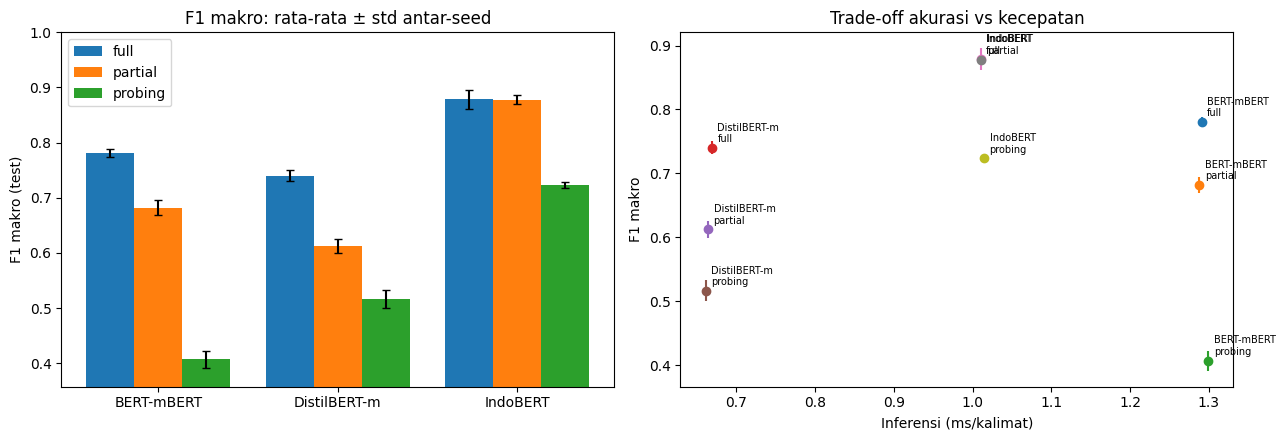

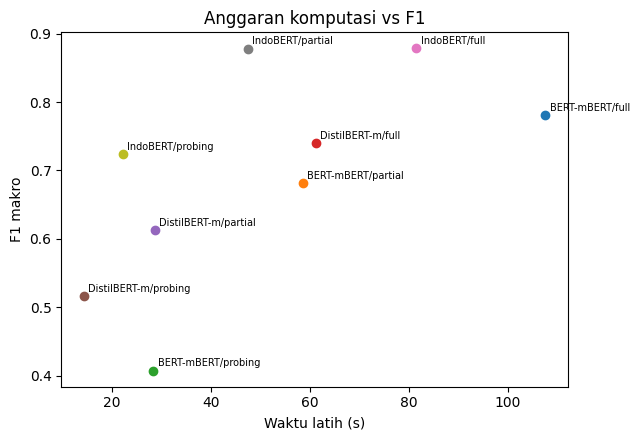

In [ ]:
# APA YANG DILAKUKAN SEL INI: membuat grafik F1 per model, trade-off akurasi vs kecepatan, dan akurasi vs waktu latih.
bbs = [b for b in B_ORDER if b in set(agg["backbone"])]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
w = 0.8 / len(S_ORDER)
for j, s in enumerate(S_ORDER):
    sub = agg[agg["strategy"] == s].set_index("backbone").reindex(bbs)
    ax[0].bar(np.arange(len(bbs)) + j * w, sub["test_f1_macro_mean"], w,
              yerr=sub["test_f1_macro_std"].fillna(0), capsize=3, label=s)
ax[0].set_xticks(np.arange(len(bbs)) + w * (len(S_ORDER) - 1) / 2); ax[0].set_xticklabels(bbs)
ax[0].set_ylabel("F1 makro (test)"); ax[0].set_title("F1 makro: rata-rata ± std antar-seed"); ax[0].legend()
lo = max(0, agg["test_f1_macro_mean"].min() - 0.05); ax[0].set_ylim(lo, 1.0)

for _, r in agg.iterrows():
    ax[1].errorbar(r["infer_ms_per_sentence_mean"], r["test_f1_macro_mean"], yerr=0 if pd.isna(r["test_f1_macro_std"]) else r["test_f1_macro_std"], fmt="o")
    ax[1].annotate(f"{r['backbone']}\n{r['strategy']}", (r["infer_ms_per_sentence_mean"], r["test_f1_macro_mean"]), fontsize=7, xytext=(4, 4), textcoords="offset points")
ax[1].set_xlabel("Inferensi (ms/kalimat)"); ax[1].set_ylabel("F1 makro"); ax[1].set_title("Trade-off akurasi vs kecepatan")
plt.tight_layout(); plt.savefig(f"grafik_{DATASET}_{KODE}.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for _, r in agg.iterrows():
    ax.scatter(r["train_time_s_mean"], r["test_f1_macro_mean"])
    ax.annotate(f"{r['backbone']}/{r['strategy']}", (r["train_time_s_mean"], r["test_f1_macro_mean"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("Waktu latih (s)"); ax.set_ylabel("F1 makro"); ax.set_title("Anggaran komputasi vs F1")
plt.tight_layout(); plt.savefig(f"grafik_biaya_{DATASET}_{KODE}.png", dpi=150); plt.show()

## 8. Bahan analisis (angka siap kutip ke laporan)

**Singkatnya:** angka-angka ini siap kamu kutip. Perhatikan selisih F1 terhadap full fine-tuning (ΔF1) beserta std-nya. Kalau |ΔF1| lebih kecil dari std-nya, dua strategi itu praktis sama.


In [ ]:
# APA YANG DILAKUKAN SEL INI: mencetak ringkasan angka (konfigurasi terbaik, selisih terhadap full, F1 per kelas) untuk dikutip ke laporan.
best = agg.sort_values("test_f1_macro_mean", ascending=False).iloc[0]
print(f"Konfigurasi F1 tertinggi: {best['backbone']} / {best['strategy']}  F1={best['test_f1_macro_mean']:.4f} ± {best['test_f1_macro_std']:.4f}")
fast = agg.sort_values("infer_ms_per_sentence_mean").iloc[0]
print(f"Inferensi tercepat: {fast['backbone']} / {fast['strategy']}  {fast['infer_ms_per_sentence_mean']:.3f} ms/kalimat (F1={fast['test_f1_macro_mean']:.4f})")

print("\n== Selisih vs full fine-tuning, per backbone (dipasangkan per seed) ==")
piv = df.pivot_table(index=["backbone", "seed"], columns="strategy", values="test_f1_macro")
tpiv = df.pivot_table(index=["backbone", "seed"], columns="strategy", values="train_time_s")
for bb in bbs:
    if bb not in piv.index.get_level_values(0): continue
    for s in ["partial", "probing"]:
        if s in piv.columns and "full" in piv.columns:
            d = (piv.loc[bb][s] - piv.loc[bb]["full"]).dropna()
            tt = (tpiv.loc[bb][s] / tpiv.loc[bb]["full"]).dropna()
            if len(d): print(f"{bb:13s} {s:8s} ΔF1 = {d.mean():+.4f} ± {d.std(ddof=1) if len(d)>1 else 0:.4f} | waktu latih {tt.mean()*100:.0f}% dari full")

print("\n== Perbandingan backbone pada full fine-tuning ==")
f = agg[agg["strategy"] == "full"].set_index("backbone")
for bb in f.index:
    print(f"{bb:13s} F1={f.loc[bb,'test_f1_macro_mean']:.4f}  infer={f.loc[bb,'infer_ms_per_sentence_mean']:.3f}ms  "
          f"param={f.loc[bb,'params_total_mean']/1e6:.1f}M  latih={f.loc[bb,'train_time_s_mean']:.0f}s")

print("\n== F1 per kelas (kelas netral biasanya paling sulit) ==")
display(agg[["backbone", "strategy", "f1_neg_mean", "f1_neu_mean", "f1_pos_mean"]].round(4))

Konfigurasi F1 tertinggi: IndoBERT / full  F1=0.8785 ± 0.0170
Inferensi tercepat: DistilBERT-m / probing  0.661 ms/kalimat (F1=0.5165)

== Selisih vs full fine-tuning, per backbone (dipasangkan per seed) ==
BERT-mBERT    partial  ΔF1 = -0.0990 ± 0.0162 | waktu latih 54% dari full
BERT-mBERT    probing  ΔF1 = -0.3736 ± 0.0228 | waktu latih 26% dari full
DistilBERT-m  partial  ΔF1 = -0.1275 ± 0.0227 | waktu latih 47% dari full
DistilBERT-m  probing  ΔF1 = -0.2235 ± 0.0155 | waktu latih 24% dari full
IndoBERT      partial  ΔF1 = -0.0003 ± 0.0217 | waktu latih 58% dari full
IndoBERT      probing  ΔF1 = -0.1547 ± 0.0176 | waktu latih 27% dari full

== Perbandingan backbone pada full fine-tuning ==
BERT-mBERT    F1=0.7808  infer=1.291ms  param=177.9M  latih=108s
DistilBERT-m  F1=0.7401  infer=0.669ms  param=135.3M  latih=61s
IndoBERT      F1=0.8785  infer=1.010ms  param=124.4M  latih=82s

== F1 per kelas (kelas netral biasanya paling sulit) ==


,backbone,strategy,f1_neg_mean,f1_neu_mean,f1_pos_mean
0,BERT-mBERT,full,0.8497,0.6425,0.8502
1,BERT-mBERT,partial,0.7743,0.5603,0.7109
2,BERT-mBERT,probing,0.4998,0.1439,0.5780
3,DistilBERT-m,full,0.8124,0.6091,0.7987
4,DistilBERT-m,partial,0.7162,0.4817,0.6398
5,DistilBERT-m,probing,0.6654,0.3662,0.5181
6,IndoBERT,full,0.9439,0.7666,0.9248
7,IndoBERT,partial,0.9496,0.7645,0.9204
8,IndoBERT,probing,0.8388,0.5303,0.8023


## 8b. Pemeriksaan hipotesis & keputusan (otomatis dari data)

Dua sel di bawah membaca hasil run dan memeriksa H1–H3 dengan angka, tanpa mengetik manual.
Aturan penilaian yang dipakai:
- Dua hasil dianggap **berbeda jelas** jika selisih rata-rata (dipasangkan per seed) lebih besar dari 2 × std selisihnya. Jika tidak, dianggap **tidak terbedakan**.
- Penurunan F1 dianggap **kecil** jika ≤ 2 poin (0,02). Ambang ini kebijakan kita sendiri, bukan standar baku, dan angkanya tidak tercantum di sel Rancangan awal (H3 hanya menyebut "kecil" tanpa angka); angka 0,02 ditetapkan di bagian ini.


In [ ]:
# APA YANG DILAKUKAN SEL INI: memeriksa H1, H2, H3 dari rancangan dengan angka hasil run.
B_FULL = "full"
f1m = agg.set_index(["backbone", "strategy"])["test_f1_macro_mean"]
f1s = agg.set_index(["backbone", "strategy"])["test_f1_macro_std"]
inf = agg.set_index(["backbone", "strategy"])["infer_ms_per_sentence_mean"]
ttm = agg.set_index(["backbone", "strategy"])["train_time_s_mean"]
piv_f1 = df.pivot_table(index=["backbone", "seed"], columns="strategy", values="test_f1_macro")
KECIL = 0.02

def beda(d):
    """d = selisih per seed. Mengembalikan (mean, std, label)."""
    m, s = d.mean(), (d.std(ddof=1) if len(d) > 1 else 0.0)
    return m, s, ("berbeda jelas" if abs(m) > 2 * s else "tidak terbedakan (dalam noise)")

print("=== H1 (backbone, full fine-tuning) ===")
urut = f1m.xs(B_FULL, level="strategy").sort_values(ascending=False)
print("Urutan F1:", " > ".join(f"{b} ({v:.4f})" for b, v in urut.items()))
print("Prediksi H1: IndoBERT > BERT-mBERT > DistilBERT-m ->",
      "TERBUKTI" if list(urut.index) == ["IndoBERT", "BERT-mBERT", "DistilBERT-m"] else "TIDAK sesuai prediksi")

print("\n=== H2 (strategi) ===")
for bb in B_ORDER:
    if bb not in f1m.index.get_level_values(0): continue
    urut_s = [s for s in S_ORDER if (bb, s) in f1m.index]
    ok = all(f1m[(bb, urut_s[i])] > f1m[(bb, urut_s[i + 1])] for i in range(len(urut_s) - 1))
    m, sd, lab = beda(piv_f1.loc[bb]["partial"] - piv_f1.loc[bb][B_FULL]) if "partial" in piv_f1.columns else (float("nan"),) * 2 + ("-",)
    print(f"{bb:13s} urutan full>partial>probing: {'ya' if ok else 'TIDAK'} | partial vs full: dF1={m:+.4f} ± {sd:.4f} -> {lab}")

print("\n=== H3 (efisiensi: DistilBERT-m vs BERT-mBERT, full) ===")
d_f1 = f1m[("DistilBERT-m", B_FULL)] - f1m[("BERT-mBERT", B_FULL)]
speed = inf[("BERT-mBERT", B_FULL)] / inf[("DistilBERT-m", B_FULL)]
print(f"Kecepatan inferensi: {speed:.2f}x lebih cepat | dF1 = {d_f1:+.4f} | waktu latih {ttm[('DistilBERT-m', B_FULL)] / ttm[('BERT-mBERT', B_FULL)] * 100:.0f}% dari mBERT")
print(f"Penurunan F1 {'<=' if -d_f1 <= KECIL else '>'} ambang 'kecil' ({KECIL}) ->",
      "H3 TERBUKTI" if -d_f1 <= KECIL else "H3 hanya SEBAGIAN terbukti (lebih cepat, tetapi penurunan F1 tidak kecil)")


=== H1 (backbone, full fine-tuning) ===
Urutan F1: IndoBERT (0.8785) > BERT-mBERT (0.7808) > DistilBERT-m (0.7401)
Prediksi H1: IndoBERT > BERT-mBERT > DistilBERT-m -> TERBUKTI

=== H2 (strategi) ===
BERT-mBERT    urutan full>partial>probing: ya | partial vs full: dF1=-0.0990 ± 0.0162 -> berbeda jelas
DistilBERT-m  urutan full>partial>probing: ya | partial vs full: dF1=-0.1275 ± 0.0227 -> berbeda jelas
IndoBERT      urutan full>partial>probing: ya | partial vs full: dF1=-0.0003 ± 0.0217 -> tidak terbedakan (dalam noise)

=== H3 (efisiensi: DistilBERT-m vs BERT-mBERT, full) ===
Kecepatan inferensi: 1.93x lebih cepat | dF1 = -0.0408 | waktu latih 57% dari mBERT
Penurunan F1 > ambang 'kecil' (0.02) -> H3 hanya SEBAGIAN terbukti (lebih cepat, tetapi penurunan F1 tidak kecil)


In [ ]:
# APA YANG DILAKUKAN SEL INI: tabel keputusan. Membandingkan 9 kombinasi pada akurasi, biaya latih, memori, dan kecepatan inferensi.
# "Tidak terdominasi" = tidak ada kombinasi lain yang sekaligus lebih akurat, lebih cepat dilatih, dan lebih cepat inferensinya.
keputusan = agg[["backbone", "strategy", "test_f1_macro_mean", "train_time_s_mean", "peak_mem_mb_mean", "infer_ms_per_sentence_mean"]].copy()
keputusan.columns = ["backbone", "strategi", "F1", "latih_s", "mem_MB", "infer_ms"]
best_f1 = keputusan["F1"].max()
keputusan["selisih_F1_vs_terbaik"] = (keputusan["F1"] - best_f1).round(4)

def terdominasi(i):
    r = keputusan.iloc[i]
    for j in range(len(keputusan)):
        if j == i: continue
        o = keputusan.iloc[j]
        lebih_baik_atau_sama = o["F1"] >= r["F1"] and o["latih_s"] <= r["latih_s"] and o["infer_ms"] <= r["infer_ms"]
        ada_yang_lebih_baik = o["F1"] > r["F1"] or o["latih_s"] < r["latih_s"] or o["infer_ms"] < r["infer_ms"]
        if lebih_baik_atau_sama and ada_yang_lebih_baik: return True
    return False

keputusan["tidak_terdominasi"] = [not terdominasi(i) for i in range(len(keputusan))]
display(keputusan.sort_values("F1", ascending=False).round(4).reset_index(drop=True))
print("Kandidat rekomendasi (tidak terdominasi):", ", ".join(
    f"{r.backbone}/{r.strategi}" for r in keputusan[keputusan["tidak_terdominasi"]].itertuples()))
print("Catatan: 'tidak terdominasi' belum berarti layak dipilih. Lihat juga kolom F1: konfigurasi ber-F1 rendah bisa lolos hanya karena murah/cepat.")


,backbone,strategi,F1,latih_s,mem_MB,infer_ms,selisih_F1_vs_terbaik,tidak_terdominasi
0,IndoBERT,full,0.8785,81.5319,3000.3887,1.0100,0.0000,True
1,IndoBERT,partial,0.8781,47.4420,1618.2324,1.0110,-0.0003,True
2,BERT-mBERT,full,0.7808,107.6260,3883.2196,1.2911,-0.0976,False
3,DistilBERT-m,full,0.7401,61.2253,2622.6025,0.6688,-0.1384,True
4,IndoBERT,probing,0.7238,22.2478,643.7975,1.0146,-0.1547,True
5,BERT-mBERT,partial,0.6819,58.5375,1957.3794,1.2881,-0.1966,False
6,DistilBERT-m,partial,0.6126,28.6659,1185.0762,0.6639,-0.2659,True
7,DistilBERT-m,probing,0.5165,14.3898,710.1802,0.6609,-0.3619,True
8,BERT-mBERT,probing,0.4073,28.3629,879.9751,1.2993,-0.4712,False


Kandidat rekomendasi (tidak terdominasi): DistilBERT-m/full, DistilBERT-m/partial, DistilBERT-m/probing, IndoBERT/full, IndoBERT/partial, IndoBERT/probing
Catatan: 'tidak terdominasi' belum berarti layak dipilih. Lihat juga kolom F1: konfigurasi ber-F1 rendah bisa lolos hanya karena murah/cepat.


In [ ]:
# APA YANG DILAKUKAN SEL INI: membandingkan tiap kombinasi dengan baseline TF-IDF dan tebakan acak.
# Panduan spesifikasi: skor di bawah baseline TF-IDF = periksa learning rate, epoch, dan loss.
cmp_ = agg[["backbone", "strategy", "test_f1_macro_mean", "test_f1_macro_std"]].copy()
cmp_.columns = ["backbone", "strategi", "F1", "SD"]
cmp_["vs TF-IDF subset"] = (cmp_["F1"] - TFIDF_F1_SUB).round(4)
cmp_["vs TF-IDF penuh"] = (cmp_["F1"] - TFIDF_F1_FULL).round(4)
def status(f):
    if f < TFIDF_F1_SUB: return "di bawah kedua baseline -> periksa LR/epoch"
    if f < TFIDF_F1_FULL: return "di atas baseline subset, di bawah baseline penuh"
    return "di atas kedua baseline"
cmp_["status"] = cmp_["F1"].apply(status)
display(cmp_.sort_values("F1", ascending=False).round(4).reset_index(drop=True))


,backbone,strategi,F1,SD,vs TF-IDF subset,vs TF-IDF penuh,status
0,IndoBERT,full,0.8785,0.0170,0.1943,0.1241,di atas kedua baseline
1,IndoBERT,partial,0.8781,0.0078,0.1939,0.1238,di atas kedua baseline
2,BERT-mBERT,full,0.7808,0.0072,0.0966,0.0265,di atas kedua baseline
3,DistilBERT-m,full,0.7401,0.0101,0.0559,-0.0143,"di atas baseline subset, di bawah baseline penuh"
4,IndoBERT,probing,0.7238,0.0055,0.0396,-0.0305,"di atas baseline subset, di bawah baseline penuh"
5,BERT-mBERT,partial,0.6819,0.0132,-0.0023,-0.0725,di bawah kedua baseline -> periksa LR/epoch
6,DistilBERT-m,partial,0.6126,0.0129,-0.0716,-0.1417,di bawah kedua baseline -> periksa LR/epoch
7,DistilBERT-m,probing,0.5165,0.0166,-0.1677,-0.2378,di bawah kedua baseline -> periksa LR/epoch
8,BERT-mBERT,probing,0.4073,0.0157,-0.2769,-0.3471,di bawah kedua baseline -> periksa LR/epoch


## 8c. Diagnostik linear probing (ablasi terpisah, bukan bagian matriks utama)

Spesifikasi menyatakan: bila linear probing berada di bawah baseline TF-IDF, **cek learning rate**. Di matriks utama, probing mBERT dan DistilBERT-m memang di bawah baseline. Sel di bawah menguji dugaan "kurang terlatih" dengan satu seed (42), dengan **learning rate lebih tinggi** (5e-3, masih dalam batas 1e-3–5e-3) dan/atau **epoch lebih banyak** (10).

Hasilnya **tidak menggantikan** tabel utama (protokol utama tetap identik untuk semua run). Ini hanya bukti pendukung untuk catatan keterbatasan. Estimasi waktu ±3–4 menit di T4. Ubah `RUN_PROBING_DIAGNOSTIC` ke `False` untuk melewatinya.


In [ ]:
# APA YANG DILAKUKAN SEL INI: menjalankan 4 run probing tambahan (seed 42) dengan LR/epoch berbeda sebagai diagnostik.
# Pengaturan LR dan epoch dikembalikan seperti semula setelah selesai, dan hasilnya TIDAK masuk ke CSV utama.
RUN_PROBING_DIAGNOSTIC = True

if RUN_PROBING_DIAGNOSTIC:
    _lr0, _ep0 = LR["probing"], CFG["epochs"]
    _diag = []
    try:
        for bb in ["IndoBERT", "BERT-mBERT"]:
            ref = df[(df.backbone == bb) & (df.strategy == "probing") & (df.seed == 42)].iloc[0]
            _diag.append(dict(backbone=bb, lr=_lr0, epoch=_ep0, keterangan="utama (referensi)",
                              test_f1=ref["test_f1_macro"], val_f1=ref["val_f1_macro"], loss_akhir=ref["final_train_loss"]))
            for lr_, ep_ in [(5e-3, _ep0), (5e-3, 10)]:
                LR["probing"], CFG["epochs"] = lr_, ep_
                r = run_one(bb, "probing", 42)
                _diag.append(dict(backbone=bb, lr=lr_, epoch=ep_, keterangan="diagnostik",
                                  test_f1=r["test_f1_macro"], val_f1=r["val_f1_macro"], loss_akhir=r["final_train_loss"]))
    except Exception as e:
        print("Diagnostik dihentikan:", repr(e))
    finally:
        LR["probing"], CFG["epochs"] = _lr0, _ep0
    if _diag:
        diag_df = pd.DataFrame(_diag)
        display(diag_df.round(4))
        out_diag = RES_FILE.replace("hasil_", "ablasi_probing_")
        if out_diag == RES_FILE: out_diag = "ablasi_probing.csv"
        diag_df.to_csv(out_diag, index=False)
        print("Disimpan ke", out_diag, "| LR dan epoch dikembalikan:", LR["probing"], CFG["epochs"])


[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `5`.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `5`.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


,backbone,lr,epoch,keterangan,test_f1,val_f1,loss_akhir
0,IndoBERT,0.002,3,utama (referensi),0.7285,0.8457,0.3393
1,IndoBERT,0.005,3,diagnostik,0.7505,0.8538,0.3217
2,IndoBERT,0.005,10,diagnostik,0.8043,0.8725,0.2908
3,BERT-mBERT,0.002,3,utama (referensi),0.3893,0.5730,0.6570
4,BERT-mBERT,0.005,3,diagnostik,0.4710,0.6743,0.6117
5,BERT-mBERT,0.005,10,diagnostik,0.5191,0.7162,0.5709


Disimpan ke ablasi_probing_smsa_9cc8e9.csv | LR dan epoch dikembalikan: 0.002 3


## Pemetaan ke ketentuan spesifikasi

| Ketentuan | Status di notebook ini |
|---|---|
| Rancangan (matriks, H1–H3, alasan, variabel terkunci) sebelum eksperimen | Ada di bagian 1; `cek_rancangan()` menolak mode full bila kosong |
| Minimal 3 backbone, protokol identik | mBERT, DistilBERT-m, IndoBERT (tanpa model English-only) |
| Minimal 3 seed per kombinasi | 42, 123, 2026 → 27 run, `n_seed = 3` di semua sel |
| Tabel: akurasi, F1 makro, waktu latih, waktu inferensi, jumlah parameter | Bagian 6 (ditambah parameter terlatih dan memori puncak) |
| Head replacement + full + (probing ATAU partial) | Full, partial, dan probing, semuanya diuji |
| Kode freezing eksplisit; LR per strategi | `apply_strategy`; LR 3e-5 (full/partial) dan 2e-3 (probing) |
| Minimal satu backbone dengan semua strategi | Ketiga backbone diuji dengan ketiga strategi |
| Urutan parameter probing < partial < full | Diverifikasi dengan `assert` di bagian 3 |
| Data: latih 3.000–6.000, validasi ≥ 500, uji resmi 500 | 5.000 / 1.246 / 500; validasi hanya untuk memilih epoch, test sekali per run |
| `set_seed()` dan pelaporan rata-rata ± SD | Dipanggil di awal `run_one`; semua tabel memakai rata-rata ± SD |
| Berkas hasil | `hasil_smsa_9cc8e9.csv`, `rekap_agregat_smsa_9cc8e9.csv` |
| Tiga pertanyaan riset (Q1–Q3) | Bagian 9 |



## 9. Kesimpulan & jawaban Pertanyaan Riset Wajib

### Evaluasi hipotesis

**H1 (backbone): terbukti.** Pada full fine-tuning, urutannya IndoBERT (0,879 ± 0,017) > mBERT (0,781 ± 0,007) > DistilBERT-m (0,740 ± 0,010). Jarak antar-model (9,8 dan 4,1 poin) jauh lebih besar dari SD (≤ 1,7 poin).

**H2 (strategi): sebagian terbukti.** Urutan full > partial > probing berlaku untuk ketiga backbone, tetapi pada IndoBERT partial (0,878 ± 0,008) tidak terbedakan dari full: ΔF1 = −0,0003 ± 0,022, jauh lebih kecil dari noise antar-seed.

**H3 (efisiensi): sebagian terbukti.** DistilBERT-m 1,93× lebih cepat saat inferensi daripada mBERT (0,67 vs 1,29 ms/kalimat) dan waktu latihnya 57% dari mBERT, tetapi F1-nya turun 4,1 poin, di atas ambang "kecil" (2 poin) yang kita pakai.

### Q1. Backbone mana yang memberi trade-off akurasi-vs-efisiensi terbaik?

**Jawaban: IndoBERT.** Angka pada full fine-tuning:

| Backbone | F1 makro ± SD | Waktu latih | Inferensi | Parameter |
|---|---|---|---|---|
| **IndoBERT** | **0,879 ± 0,017** | 82 s | 1,01 ms/kalimat | 124,4 M |
| mBERT | 0,781 ± 0,007 | 108 s | 1,29 ms/kalimat | 177,9 M |
| DistilBERT-m | 0,740 ± 0,010 | **61 s** | **0,67 ms/kalimat** | 135,3 M |

IndoBERT paling akurat (+9,8 poin atas mBERT, jauh melampaui SD), lebih cepat dilatih dan lebih cepat inferensi dari mBERT, dan punya parameter paling sedikit. DistilBERT-m memang paling cepat (1,5× lebih cepat inferensi dari IndoBERT), tetapi harganya 13,8 poin F1. Ia juga tidak lebih kecil dari IndoBERT (135 M vs 124 M); dugaan saya penyebabnya vocab multibahasa yang besar, tetapi itu belum diuji. Jadi tidak ada trade-off yang mengharuskan kita mengorbankan akurasi: IndoBERT unggul di hampir semua sisi. Pembanding: baseline TF-IDF F1 makro 0,754 (data penuh) dan 0,684 (subset 5.000). DistilBERT-m full (0,740) berada di atas baseline subset tetapi sedikit di bawah baseline data penuh.

### Q2. Apakah strategi hemat komputasi (probing/partial) cukup kompetitif?

**Jawaban: partial ya, tetapi hanya untuk IndoBERT. Probing pada protokol utama tidak.** Selisih terhadap full dibandingkan dengan SD antar-seed:

- **IndoBERT partial:** ΔF1 = −0,0003 ± 0,022, jadi **tidak bermakna** (di dalam noise). Waktu latih turun ±42% (47 s vs 82 s) dan memori puncak ±46% (1,6 GB vs 3,0 GB).
- **mBERT partial:** ΔF1 = −0,099 ± 0,016 dan **DistilBERT-m partial:** ΔF1 = −0,128 ± 0,023: **bermakna**, jauh melebihi SD. Keduanya juga di dekat atau di bawah baseline TF-IDF subset.
- **Linear probing:** turun paling jauh di semua backbone (IndoBERT 0,724, ΔF1 −0,155 ± 0,018; mBERT 0,407, ΔF1 −0,374 ± 0,023; DistilBERT-m 0,517, ΔF1 −0,224 ± 0,016). Di protokol utama IndoBERT probing hanya di atas baseline subset (0,684) dan di bawah baseline penuh (0,754).
- **Diagnostik (sel 8c, satu seed, bukan bagian matriks utama):** dengan LR 5e-3 dan 10 epoch, F1 probing IndoBERT naik dari 0,729 menjadi 0,804 dan mBERT dari 0,389 menjadi 0,519, sementara loss turun (IndoBERT 0,339 → 0,291; mBERT 0,657 → 0,571). Jadi probing di protokol utama memang kurang terlatih. Namun, bahkan dengan 10 epoch IndoBERT probing masih ±7 poin di bawah partial (0,804 vs 0,878), dan waktu latihnya (perkiraan kasar ±74 s, yaitu 22 s × 10/3; tidak diukur langsung) tidak lebih murah dari partial (47 s). mBERT probing tetap di bawah baseline.

### Q3. Kombinasi apa yang direkomendasikan, dan mengapa?

**Kriteria ditetapkan dulu** :
1. **Akurasi:** F1 tidak berbeda bermakna dari yang terbaik (selisih < 2 × SD) dan di atas baseline TF-IDF.
2. **Anggaran komputasi:** muat di GPU T4 gratis, dengan waktu latih dan memori sehemat mungkin.
3. **Kecepatan inferensi:** ≤ 1,5 ms/kalimat pada GPU T4 (terukur di notebook; batas ini usulan kelompok untuk latensi interaktif dan tidak tercantum di sel Rancangan awal).
4. **Keterjelasan:** setiap klaim didukung angka dari eksperimen terkontrol dan selisihnya lebih besar dari SD.

**Rekomendasi: IndoBERT + partial freezing.** F1 0,878 ± 0,008 (tidak berbeda bermakna dari full dan jauh di atas kedua baseline; lolos kriteria 1), waktu latih ±47 s vs 82 s dan memori puncak ±1,6 GB vs 3,0 GB (kriteria 2), inferensi 1,01 ms (kriteria 3), dan setiap klaim didukung selisih yang dibandingkan dengan SD (kriteria 4). Cadangan: **IndoBERT full** bila F1 mutlak tertinggi (0,879 ± 0,017; akurasi 0,909; selisihnya dengan partial tidak bermakna) lebih penting dan memori ±3 GB tidak masalah. Freezing tidak mempercepat inferensi, jadi bila latensi di bawah ±0,7 ms mutlak diperlukan, satu-satunya opsi adalah DistilBERT-m dengan harga F1 ±14 poin.

### Catatan keterbatasan

1. **Data latih 5.000 kalimat** (batas spesifikasi 3.000–6.000), jadi hasil bisa berbeda dengan data penuh.
2. **Hanya 3 seed,** dengan subset latih yang sama di semua seed, sehingga SD kemungkinan lebih kecil dari variasi sebenarnya.
3. **Data test hanya 500 kalimat** (1 kalimat ≈ 0,2%). Selisih di bawah ±1 poin tidak dapat dipercaya.
4. **Epoch maksimum dikunci 3 untuk semua run,** dan epoch terbaik dipilih berdasarkan F1 validasi (`select_best_epoch=True`), bukan data test. Data test hanya disentuh sekali per run, sehingga tidak ada kebocoran.
5. **Reproduksibilitas tidak dijamin penuh.** Seed dikunci, tetapi nondeterminisme operasi GPU (dan AMP fp16) dapat menggeser F1 beberapa persepuluh poin pada eksekusi ulang. Angka di notebook ini berasal dari satu eksekusi penuh; ini dugaan, belum diuji dengan eksekusi ulang.
6. **Linear probing tidak sepenuhnya apple-to-apple.** Head DistilBERT punya lapisan tambahan yang ikut dilatih (±0,6 M parameter), sedangkan mBERT dan IndoBERT hanya satu lapisan linear (±2 ribu parameter). Probing dengan 3 epoch juga kurang terlatih (lihat diagnostik 8c).
7. **Kelas netral paling sulit** di semua model dan paling sedikit datanya (IndoBERT full: F1 netral 0,77 vs 0,92–0,94 untuk kelas lain).
8. **Dropout tetap aktif di lapisan yang dibekukan** (model dalam mode train), sehingga partial/probing sedikit terpengaruh noise dropout; ini bisa ikut menjelaskan probing yang kurang terlatih.
9. **Heuristik "selisih > 2×SD" dengan n = 3 seed** kasar dan bukan uji statistik; SD dari 3 sampel sendiri tidak stabil.
10. **Tabel "tidak terdominasi" (sel 8b) tidak memasukkan memori puncak,** jadi kandidatnya bisa berbeda bila memori dihitung, dan konfigurasi ber-F1 rendah bisa lolos hanya karena murah.
11. **Distribusi kelas data test berbeda dari data latih,** sehingga F1 makro per kelas (terutama netral) perlu dibaca hati-hati.
12. **Satu dataset, satu GPU (T4).** Waktu inferensi hanya valid dalam satu sesi. XLM-R (opsional) tidak diuji.
13. **Ablasi dropout tidak dijalankan.** Pada probing/partial, backbone beku tetap dalam mode `train()` (lihat butir 8). Menjalankan backbone beku dalam mode `eval()` belum diuji, sehingga seberapa besar dropout memengaruhi skor probing belum diketahui.
14. **Peringatan `num_labels=3` vs `id2label` panjang 5 pada IndoBERT.** Config bawaan IndoBERT memiliki 5 label. Ukuran head tetap benar (2.307 parameter = 768×3+3, lihat tabel parameter), sehingga pelatihan dan metrik tidak terpengaruh. Isi `model.config.id2label` tidak diperiksa langsung.
15. **Kode konfigurasi (`9cc8e9`) dihitung dari mode, CFG, LR, dan backbone, tidak dari daftar seed dan strategi.** Semua hasil di notebook ini berasal dari satu konfigurasi dengan seed [42, 123, 2026] dan 3 strategi, jadi tidak ada hasil yang tercampur. Bila seed atau strategi diubah, hapus file hasil lama.
16. **Baseline TF-IDF kami (0,754, data penuh) sedikit lebih tinggi dari patokan spesifikasi (≈ 0,73).** Kesimpulan tidak berubah: baseline yang lebih kuat hanya membuat perbandingan dengan Transformer lebih ketat.
